# QFF 2026 Phase 1 - PS-O1: Weighted Max-Cut

**Inderpreet Kaur and Harshit Tripathi.** This notebook regenerates both allowed QAOA depths, all classical references, A/B compilations, exact and sampled noise results, and the saved figures. Run every cell in the project root using the pinned local environment.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT / 'src/routing.py').is_file(), 'Run from the project root'
for package in ['qiskit', 'qiskit-aer', 'numpy', 'pandas', 'networkx', 'scipy']:
    print(package, metadata.version(package))
from src.problem import build_weighted_graph, build_cost_hamiltonian, cost_diagonal
from run_experiment import initial_classical_stage, run_qaoa_stage

qiskit 2.5.0
qiskit-aer 0.17.2
numpy 2.3.5
pandas 2.3.3
networkx 3.6.1
scipy 1.17.0


## Objective and five-qubit reduction

The guide specifies six graph nodes but Processor A has five physical qubits. Complement symmetry lets us fix node 0 to zero, preserving all objective values. The remaining five bits define the reduced QAOA ansatz; its finite-depth state need not equal a six-qubit mixer state. Topology seed and documented weight seed are both 42.

Classical reference: 6 nodes, 9 edges, optimum 22; full enumeration verified.


Classical optimum: 22


,u,v,weight
0,0,2,1
1,0,3,4
2,0,4,4
3,1,4,3
4,1,5,3
5,2,3,5
6,2,4,1
7,3,4,4
8,3,5,2


,reduced_index,node_bits_0_to_5,selected_group_A_nodes,selected_group_B_nodes,cut_value
0,26,001011,"0,1,3","2,4,5",22
1,5,010100,"0,2,4,5","1,3",21
2,28,000111,"0,1,2","3,4,5",20
3,12,000110,"0,1,2,5","3,4",19
4,13,010110,"0,2,5","1,3,4",19


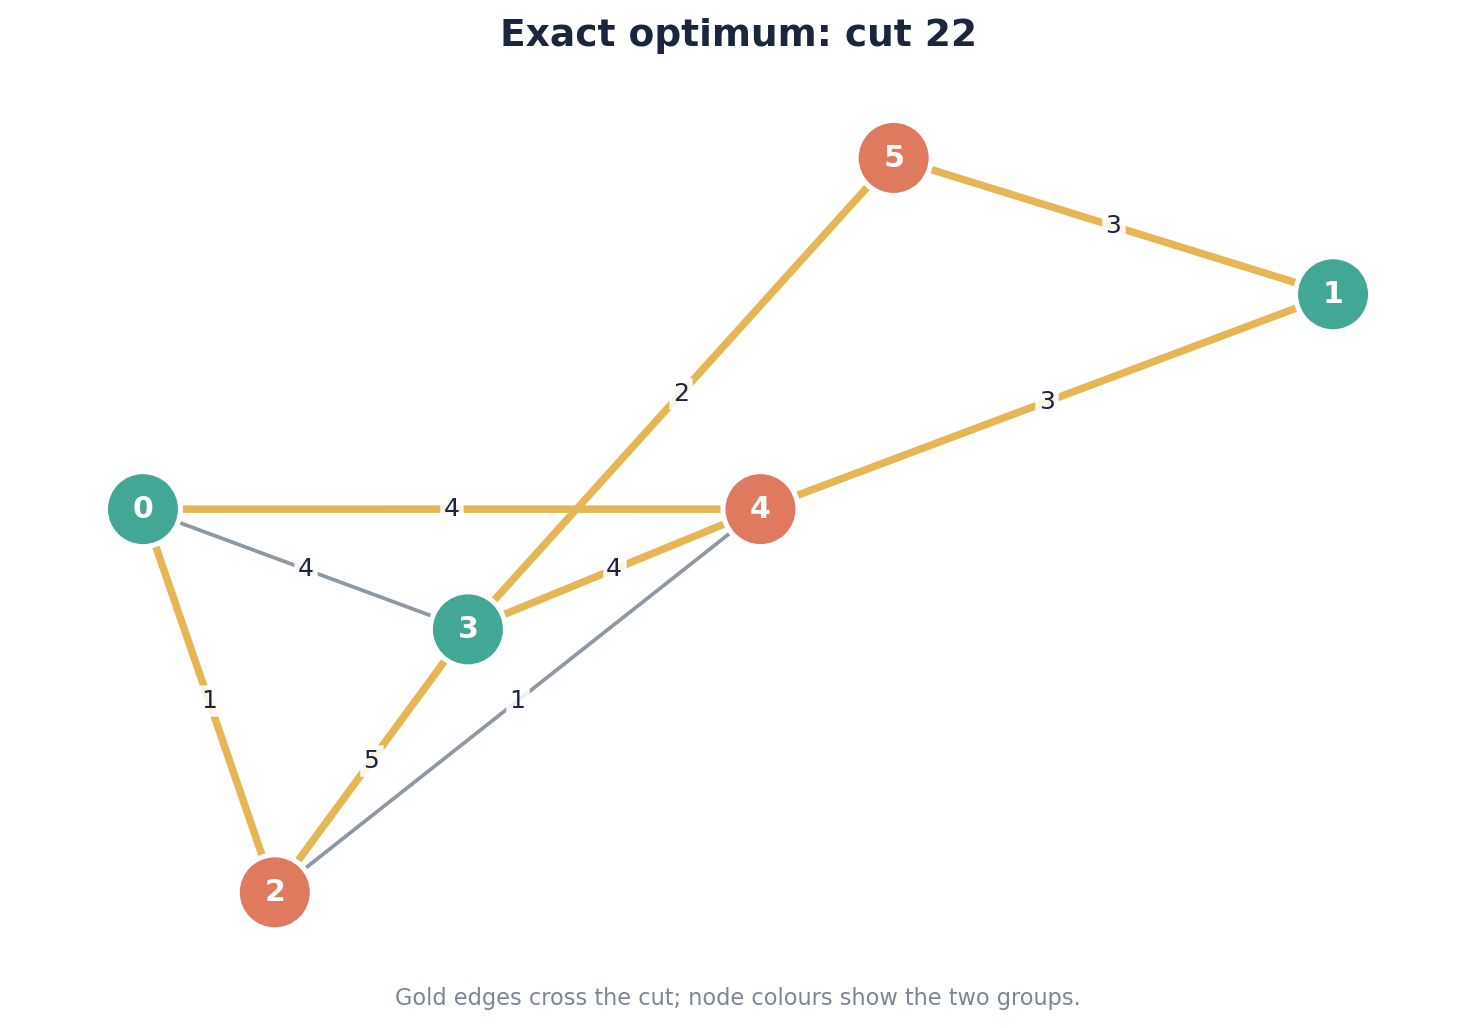

In [2]:
graph = build_weighted_graph()
optimum, classical_assignment = initial_classical_stage(graph)
print('Classical optimum:', optimum)
display(pd.read_csv(ROOT / 'data/raw/maxcut_edges.csv'))
display(pd.read_csv(ROOT / 'results/tables/classical_all_cuts.csv', dtype={'node_bits_0_to_5': str}).head())
display(Image(filename=str(ROOT / 'results/figures/02_classical_optimum_cut.png')))

## Cost Hamiltonian

$C=\sum_{(u,v)}w_{uv}(I-Z_u Z_v)/2$, with $Z_0=+1$. Every Hamiltonian eigenvalue is checked against a classical cut. QAOA applies `RZ(-gamma*w)`, `RZZ(-gamma*w)`, then `RX(2*beta)`.

In [3]:
hamiltonian = build_cost_hamiltonian(graph)
print(hamiltonian)
np.testing.assert_allclose(hamiltonian.to_matrix(), np.diag(cost_diagonal(graph)), atol=1e-12)
print('All 32 Hamiltonian eigenvalues match the reduced objective.')

SparsePauliOp(['IIIII', 'IIIZI', 'IIZII', 'IZIII', 'IZIIZ', 'ZIIIZ', 'IIZZI', 'IZIZI', 'IZZII', 'ZIZII'],
              coeffs=[13.5+0.j, -0.5+0.j, -2. +0.j, -2. +0.j, -1.5+0.j, -1.5+0.j, -2.5+0.j,
 -0.5+0.j, -2. +0.j, -1. +0.j])
All 32 Hamiltonian eigenvalues match the reduced objective.


## Processor designs

A is a five-qubit chain. B is a connected nine-qubit graph with a core tailored to the six free-variable interactions. Angles, initial layout, native basis, transpiler level/seed and noise rates are held fixed across the comparison. B's spare physical qubits are idle in the primary run.

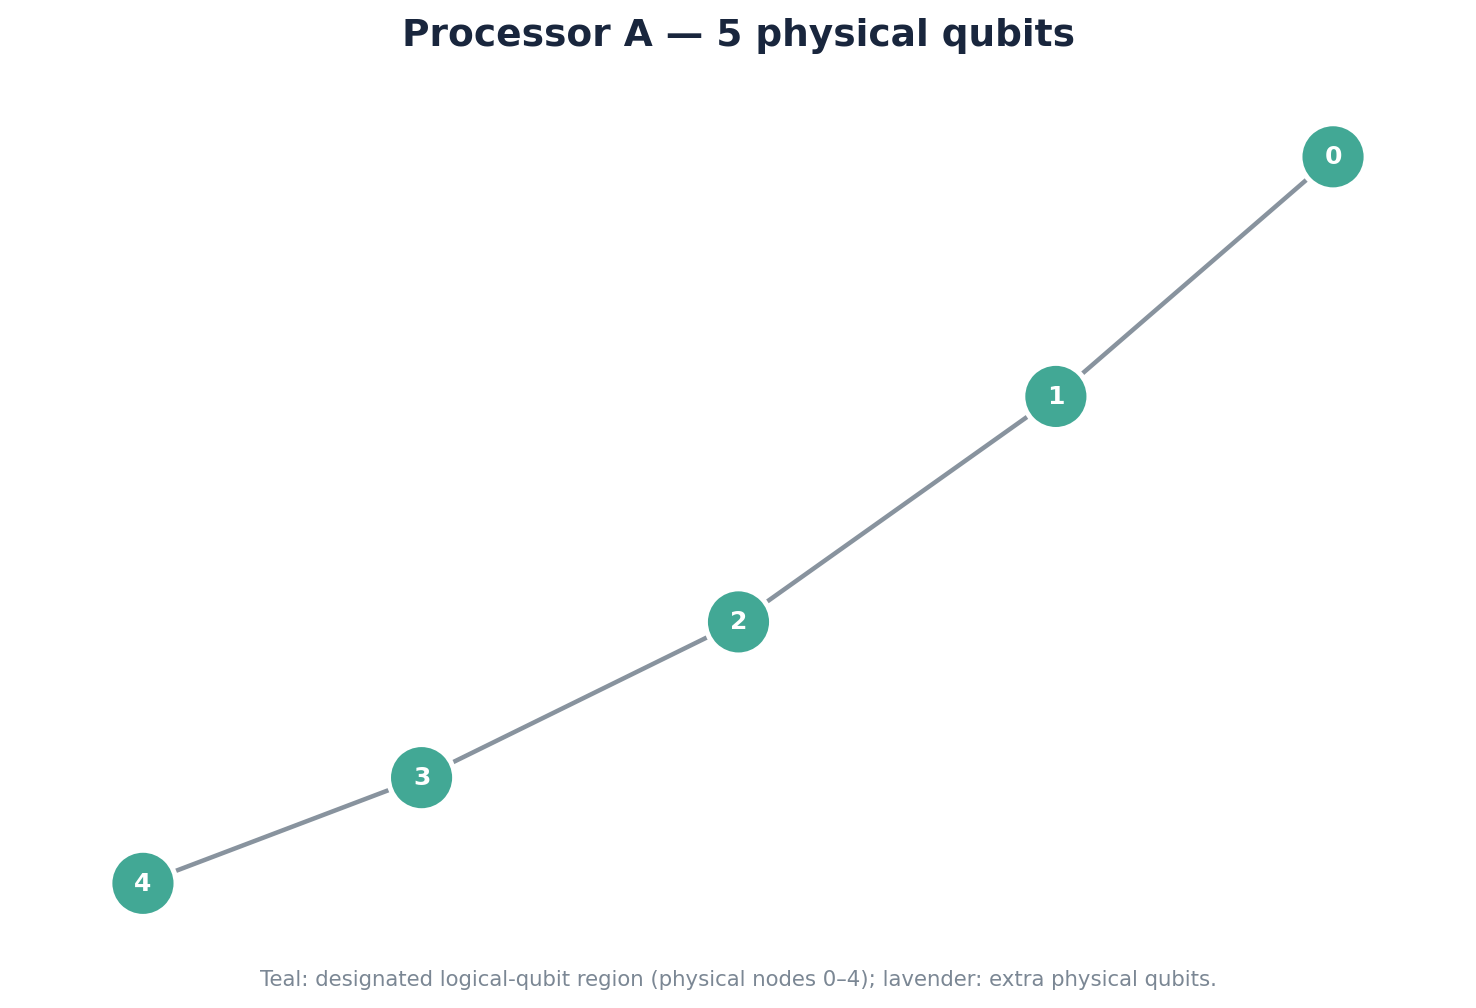

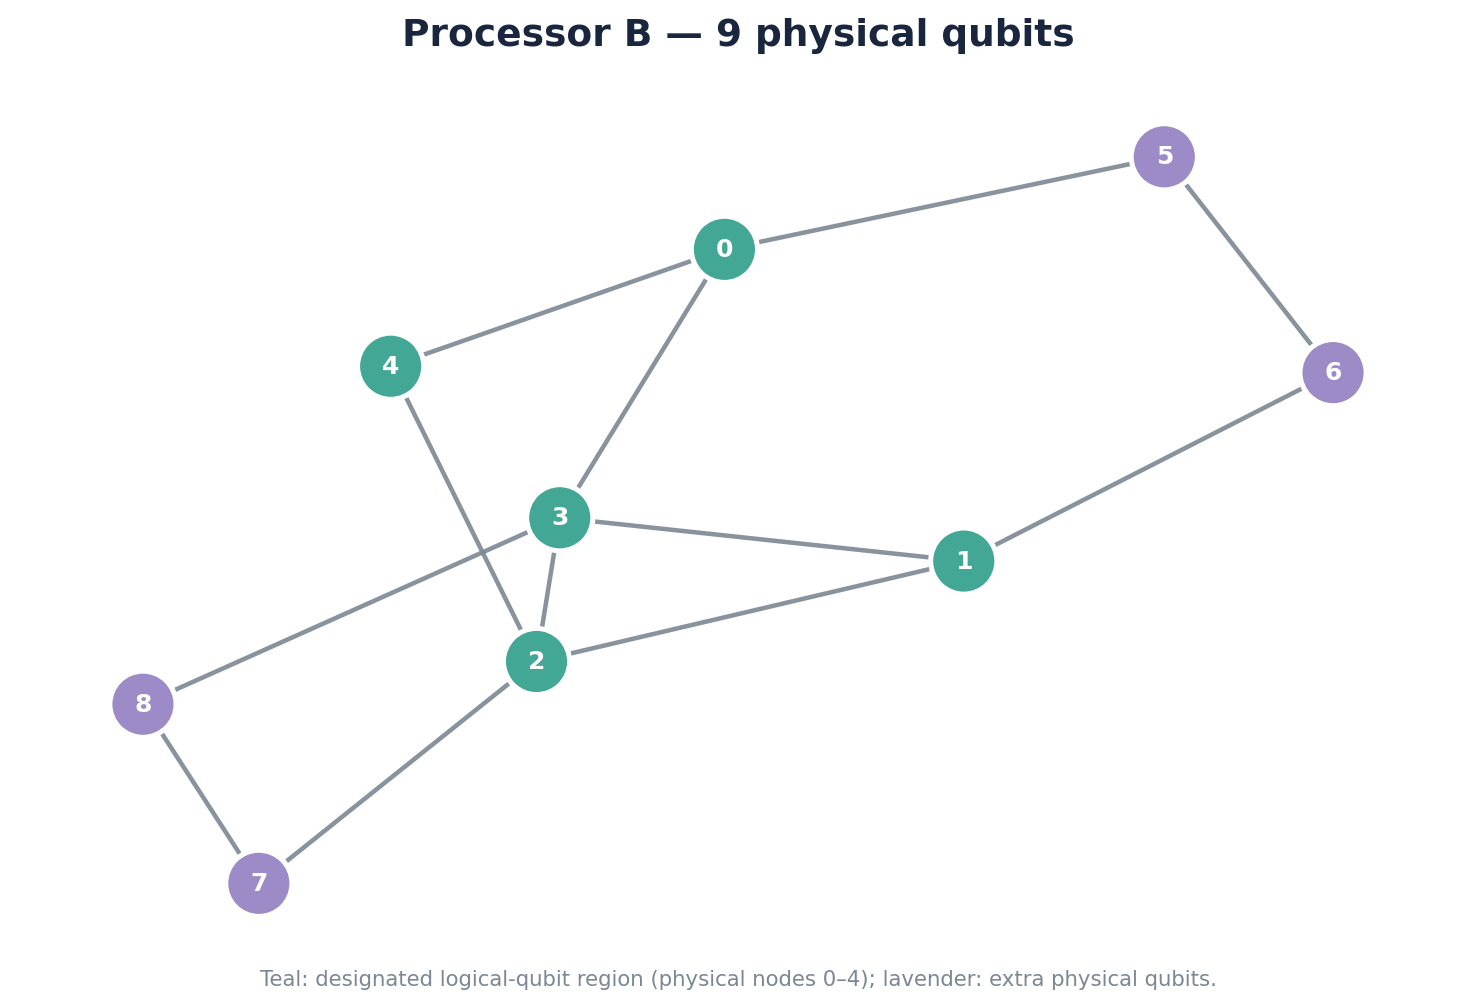

In [4]:
for name in ['A', 'B']:
    display(Image(filename=str(ROOT / f'results/figures/architecture_processor_{name}.png')))

## Run both allowed QAOA depths

Optimize p=1 with grid-seeded 16-start COBYLA, then warm-start p=2 with the p=1 result and additional starts. Each architecture has 4096 shots per evaluation, five sampling seeds, ideal/noisy evaluation, and exact noisy density-matrix probabilities. This cell recreates the data and figures from scratch.

In [5]:
p1 = run_qaoa_stage(graph, optimum, classical_assignment, depth=1, shots=4096, seed=42, repeats=5, restarts=16, maxiter=800)
p2 = run_qaoa_stage(graph, optimum, classical_assignment, depth=2, shots=4096, seed=42, repeats=5, restarts=16, maxiter=800, warm_start=(p1['gammas'], p1['betas']))
assert p2['best_ideal_expected_cut'] >= p1['best_ideal_expected_cut']
print('Exact ideal expected cuts:', p1['best_ideal_expected_cut'], p2['best_ideal_expected_cut'])

Optimizing QAOA p=1: 16 starts, up to 800 COBYLA evaluations/start...


  Compiling Processor A and checking logical equivalence...


  Processor A: depth 38, CX 27, SWAPs 5, noisy mean 17.2183


  Compiling Processor B and checking logical equivalence...


  Processor B: depth 21, CX 12, SWAPs 0, noisy mean 17.3914


...

  Processor A: depth 69, CX 51, SWAPs 9, noisy mean 18.1768


  Compiling Processor B and checking logical equivalence...


  Processor B: depth 38, CX 24, SWAPs 0, noisy mean 18.5635


Completed p=2; exact optimized mean 19.240690, ratio 0.874577.


Exact ideal expected cuts: 17.64299292586879 19.240689773382066


## Quantitative architecture and solution comparisons

Depth includes measurement. SWAPs are captured after routing in the actual compilation pipeline. Classical distribution fidelity measures output probabilities, not quantum state fidelity. The mean approximation ratio is mean cut/22, even when the best sample reaches 22.

QAOA p=1


,processor,circuit_depth,cx_count,routing_swap_count,exact_logical_expected_cut,exact_noisy_expected_cut,exact_noisy_approximation_ratio,noisy_expected_cut_from_shots,noisy_cut_mean_standard_error,noisy_optimal_cut_shot_rate,noisy_best_observed_cut
0,Processor A,38,27,5,17.642993,17.152991,0.779681,17.218262,0.060538,0.138672,22
1,Processor B,21,12,0,17.642993,17.318042,0.787184,17.391357,0.058485,0.143066,22


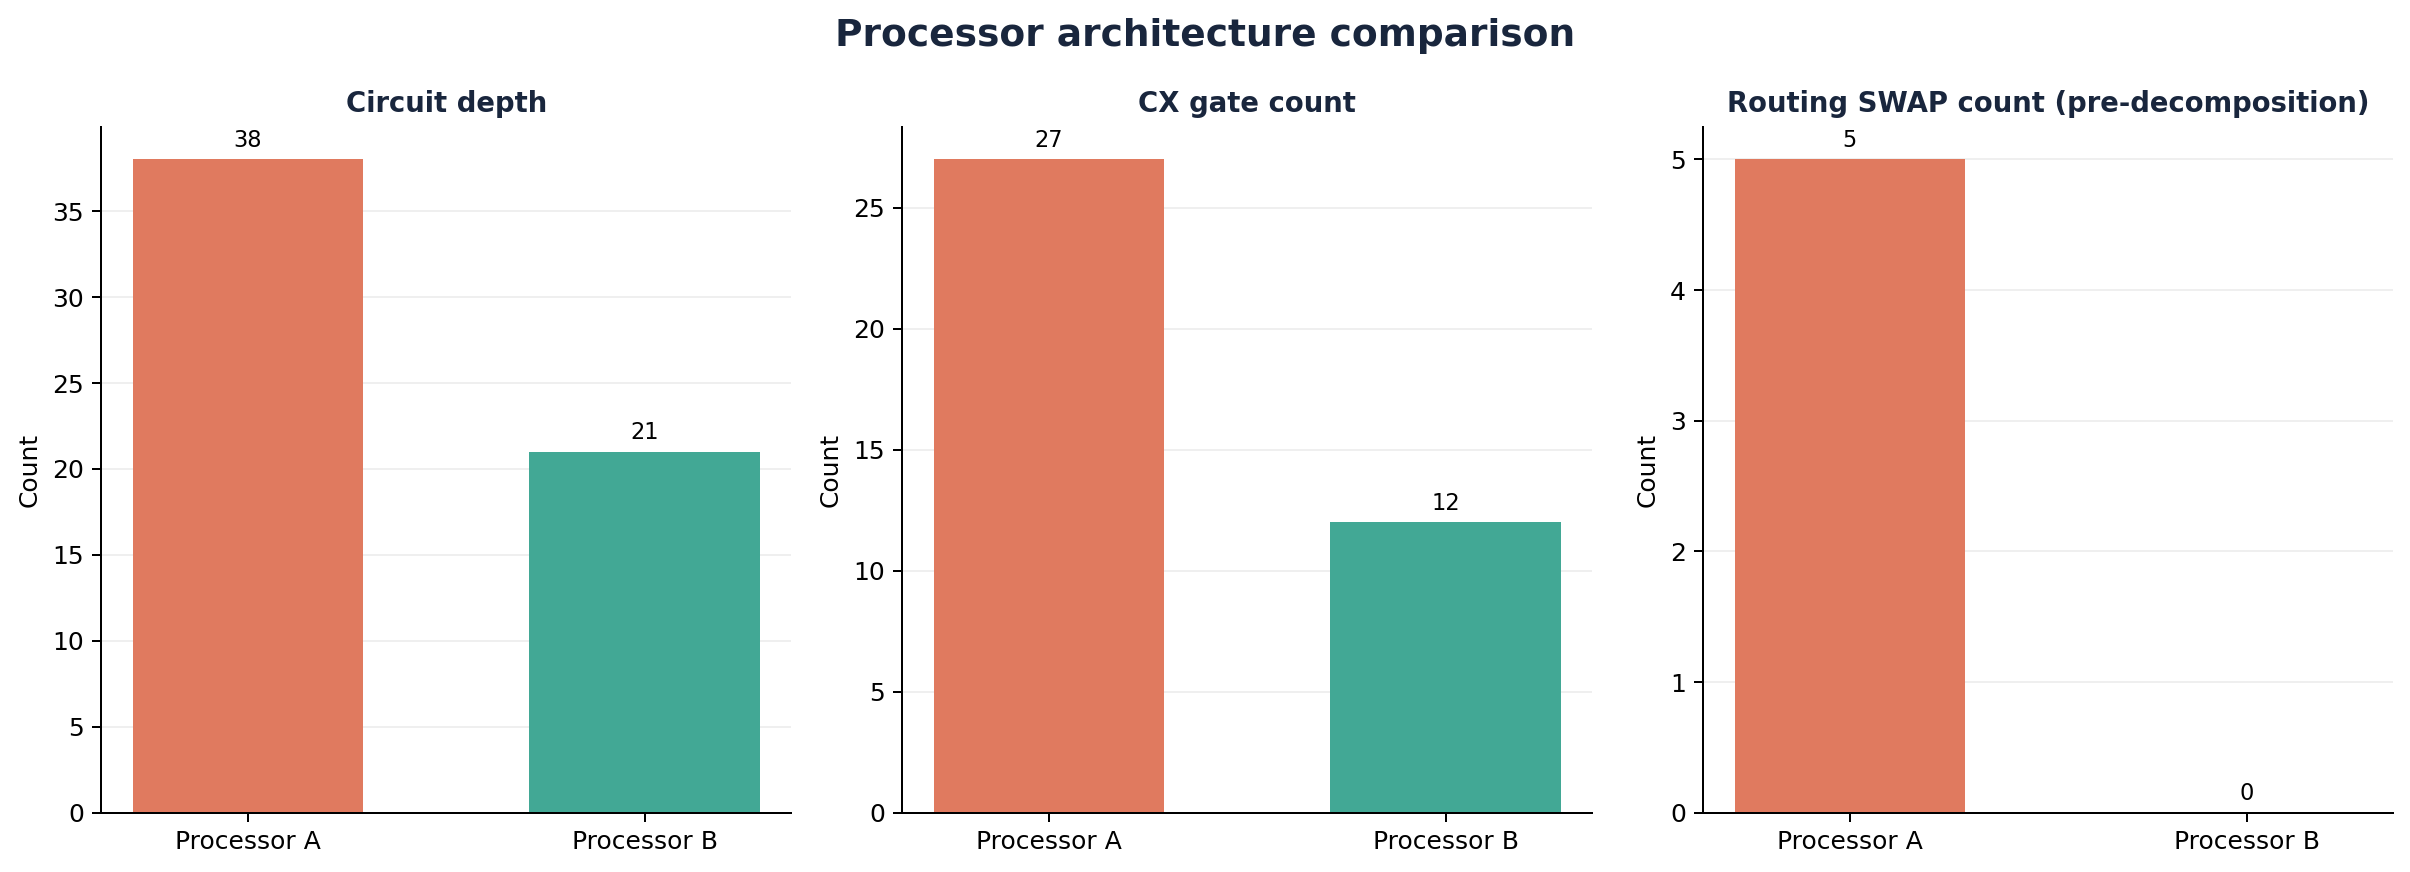

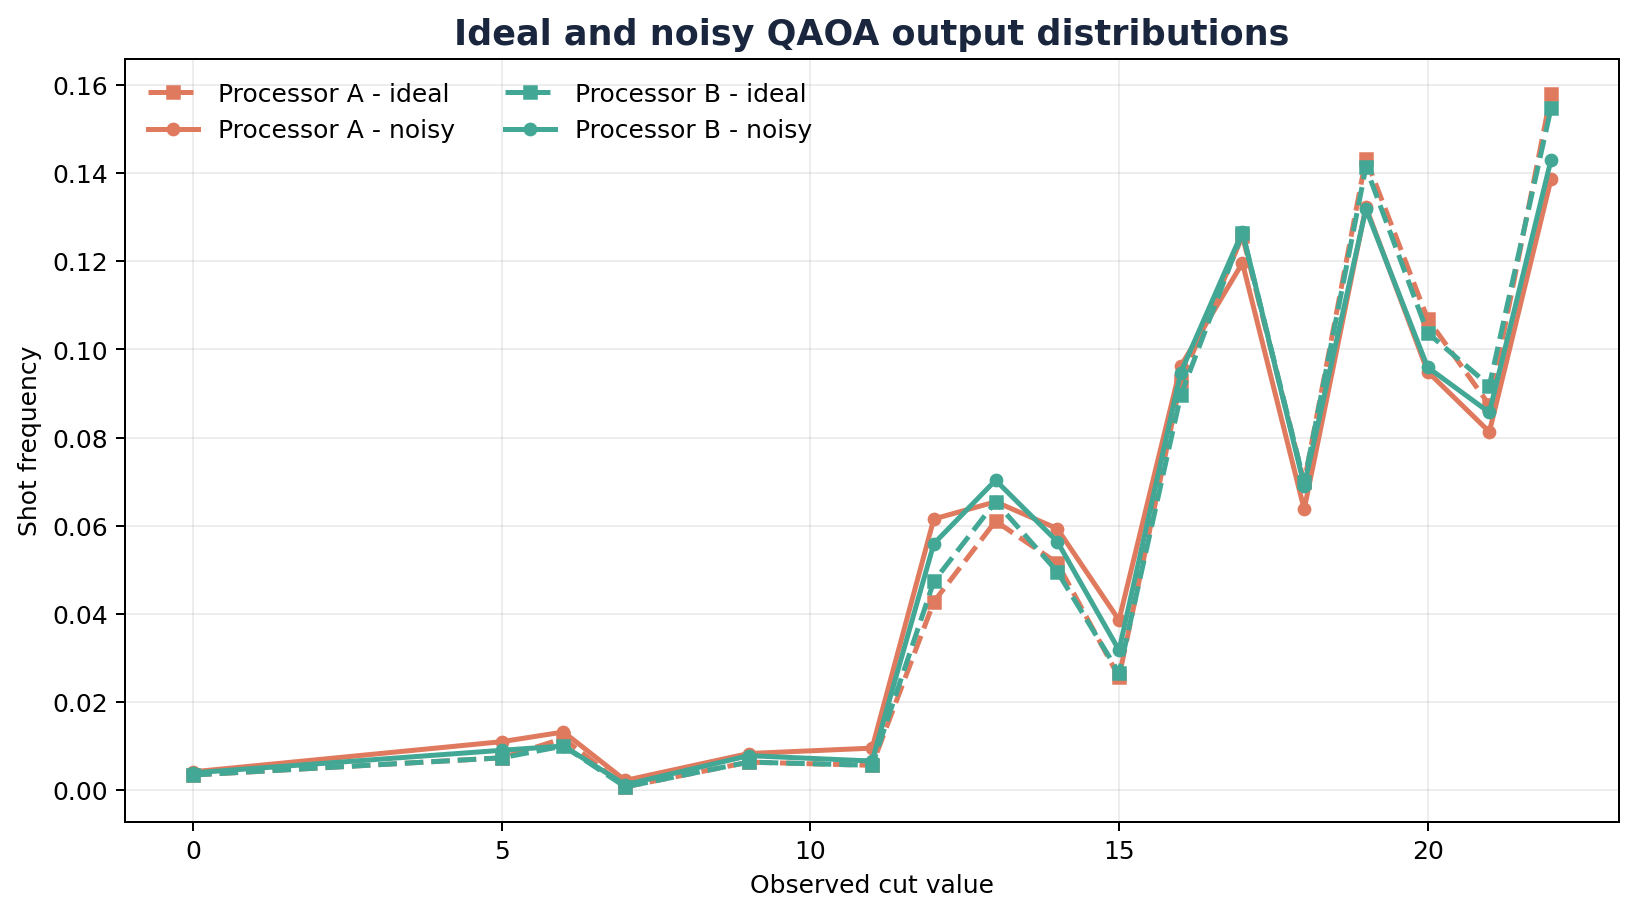

QAOA p=2


,processor,circuit_depth,cx_count,routing_swap_count,exact_logical_expected_cut,exact_noisy_expected_cut,exact_noisy_approximation_ratio,noisy_expected_cut_from_shots,noisy_cut_mean_standard_error,noisy_optimal_cut_shot_rate,noisy_best_observed_cut
0,Processor A,69,51,9,19.24069,18.176282,0.826195,18.176758,0.059743,0.190674,22
1,Processor B,38,24,0,19.24069,18.563090,0.843777,18.563477,0.054468,0.204590,22


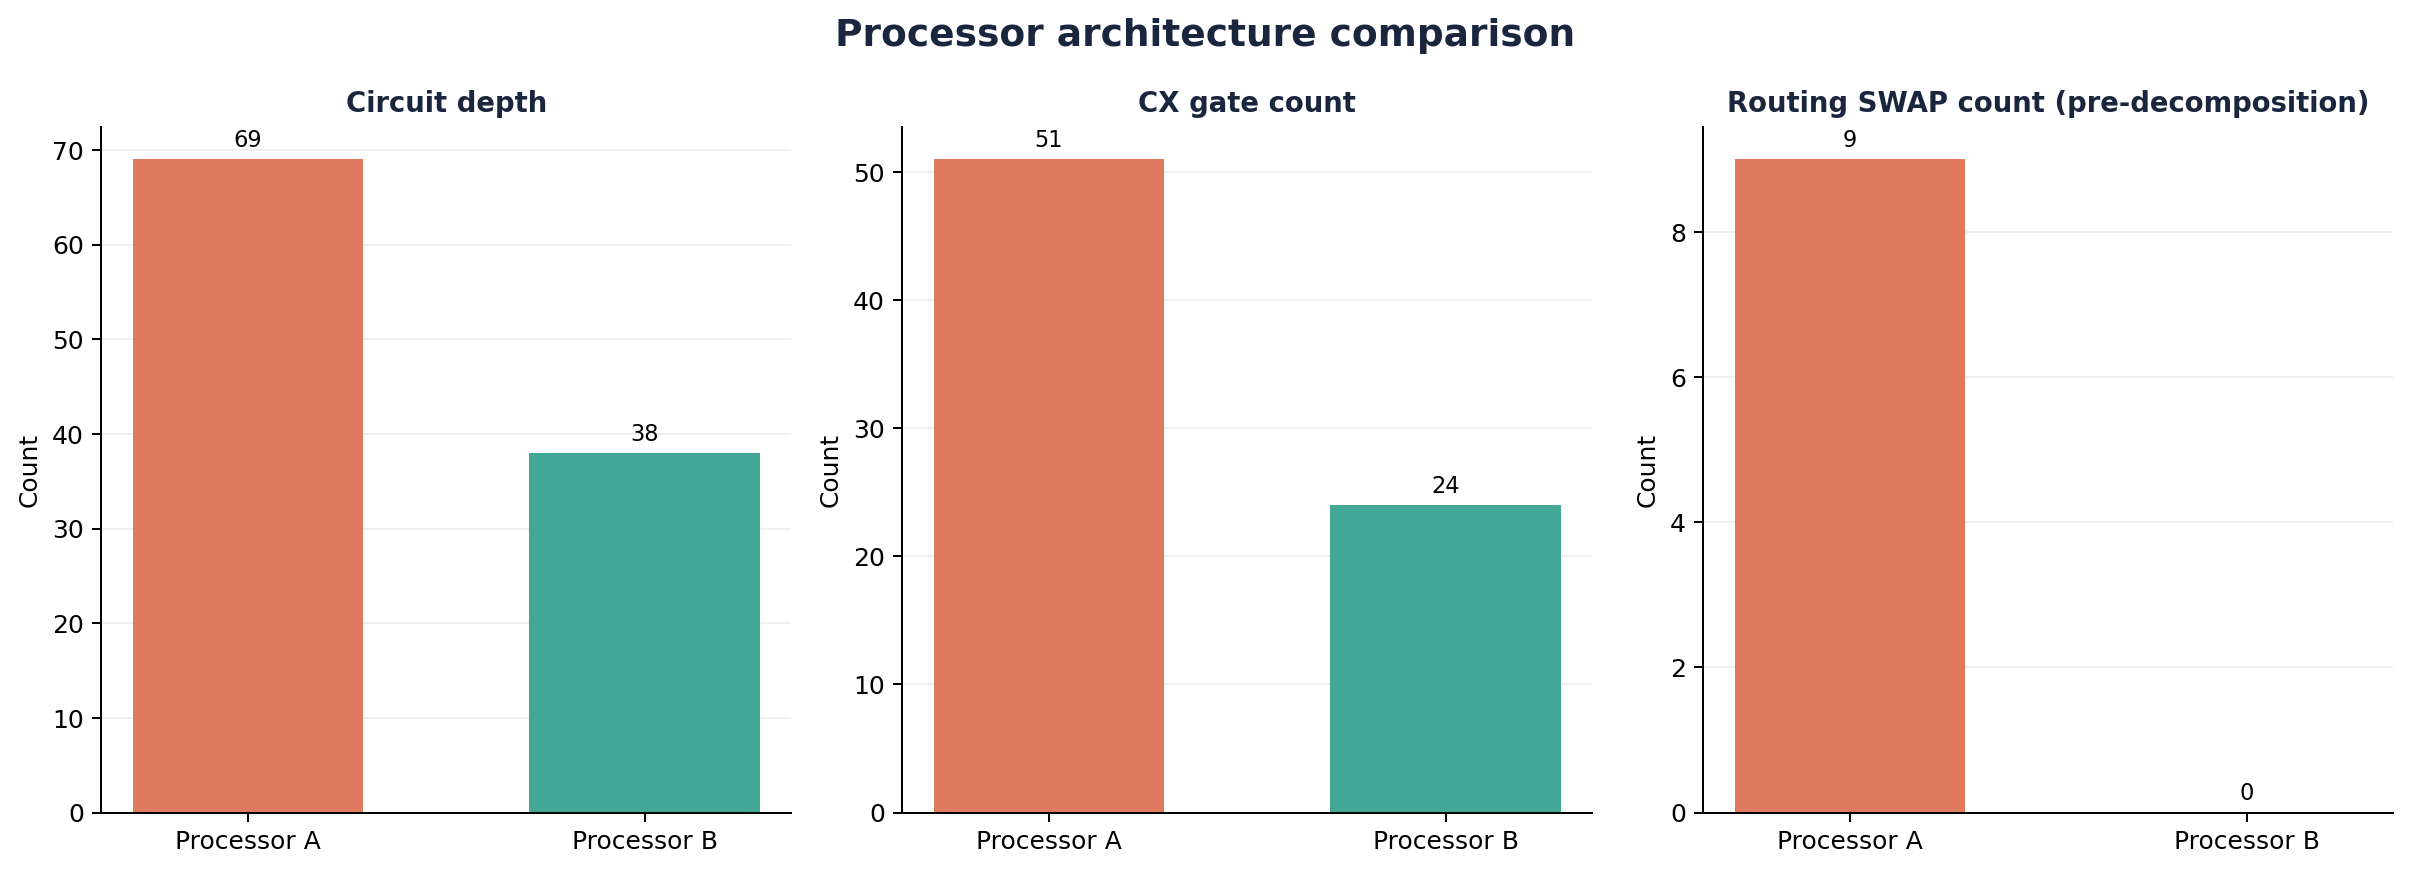

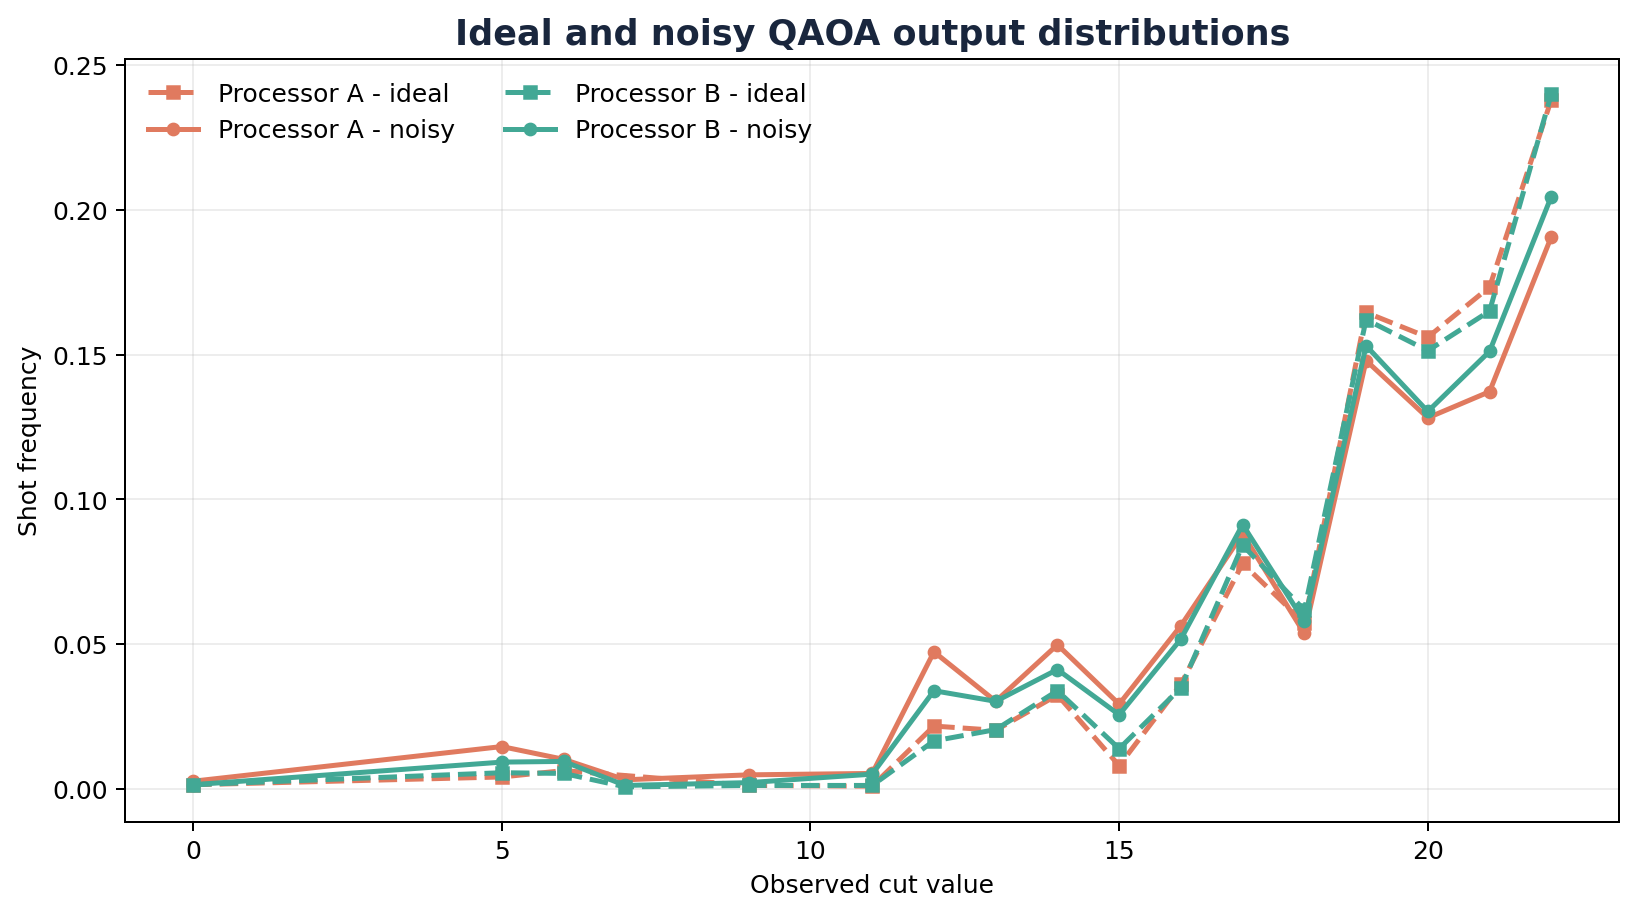

In [6]:
columns = ['processor', 'circuit_depth', 'cx_count', 'routing_swap_count', 'exact_logical_expected_cut', 'exact_noisy_expected_cut', 'exact_noisy_approximation_ratio', 'noisy_expected_cut_from_shots', 'noisy_cut_mean_standard_error', 'noisy_optimal_cut_shot_rate', 'noisy_best_observed_cut']
for depth in [1, 2]:
    print(f'QAOA p={depth}')
    display(pd.read_csv(ROOT / f'results/tables/processor_comparison_p{depth}.csv')[columns])
    display(Image(filename=str(ROOT / f'results/figures/processor_comparison_p{depth}.png')))
    display(Image(filename=str(ROOT / f'results/figures/noisy_cut_distribution_p{depth}.png')))

## Sampling repetitions and exact optimum

Each of five repetitions still uses 4096 shots, as specified by the guide. Exact noisy predictions isolate the modeled noise effect; repetition variation describes measurement sampling. A sampled optimum is not evidence that every shot is optimal.

mean_cut  between_run_sd  mean_optimal_rate
processor   mode                                               
Processor A ideal  17.652881        0.041818           0.154248
            noisy  17.150977        0.041526           0.134912
Processor B ideal  17.668066        0.018373           0.154688
            noisy  17.340625        0.030197           0.140820

mean_cut  between_run_sd  mean_optimal_rate
processor   mode                                               
Processor A ideal  19.249854        0.029940           0.232666
            noisy  18.190723        0.049256           0.185059
Processor B ideal  19.237988        0.048699           0.234766
            noisy  18.566943        0.034480           0.201172

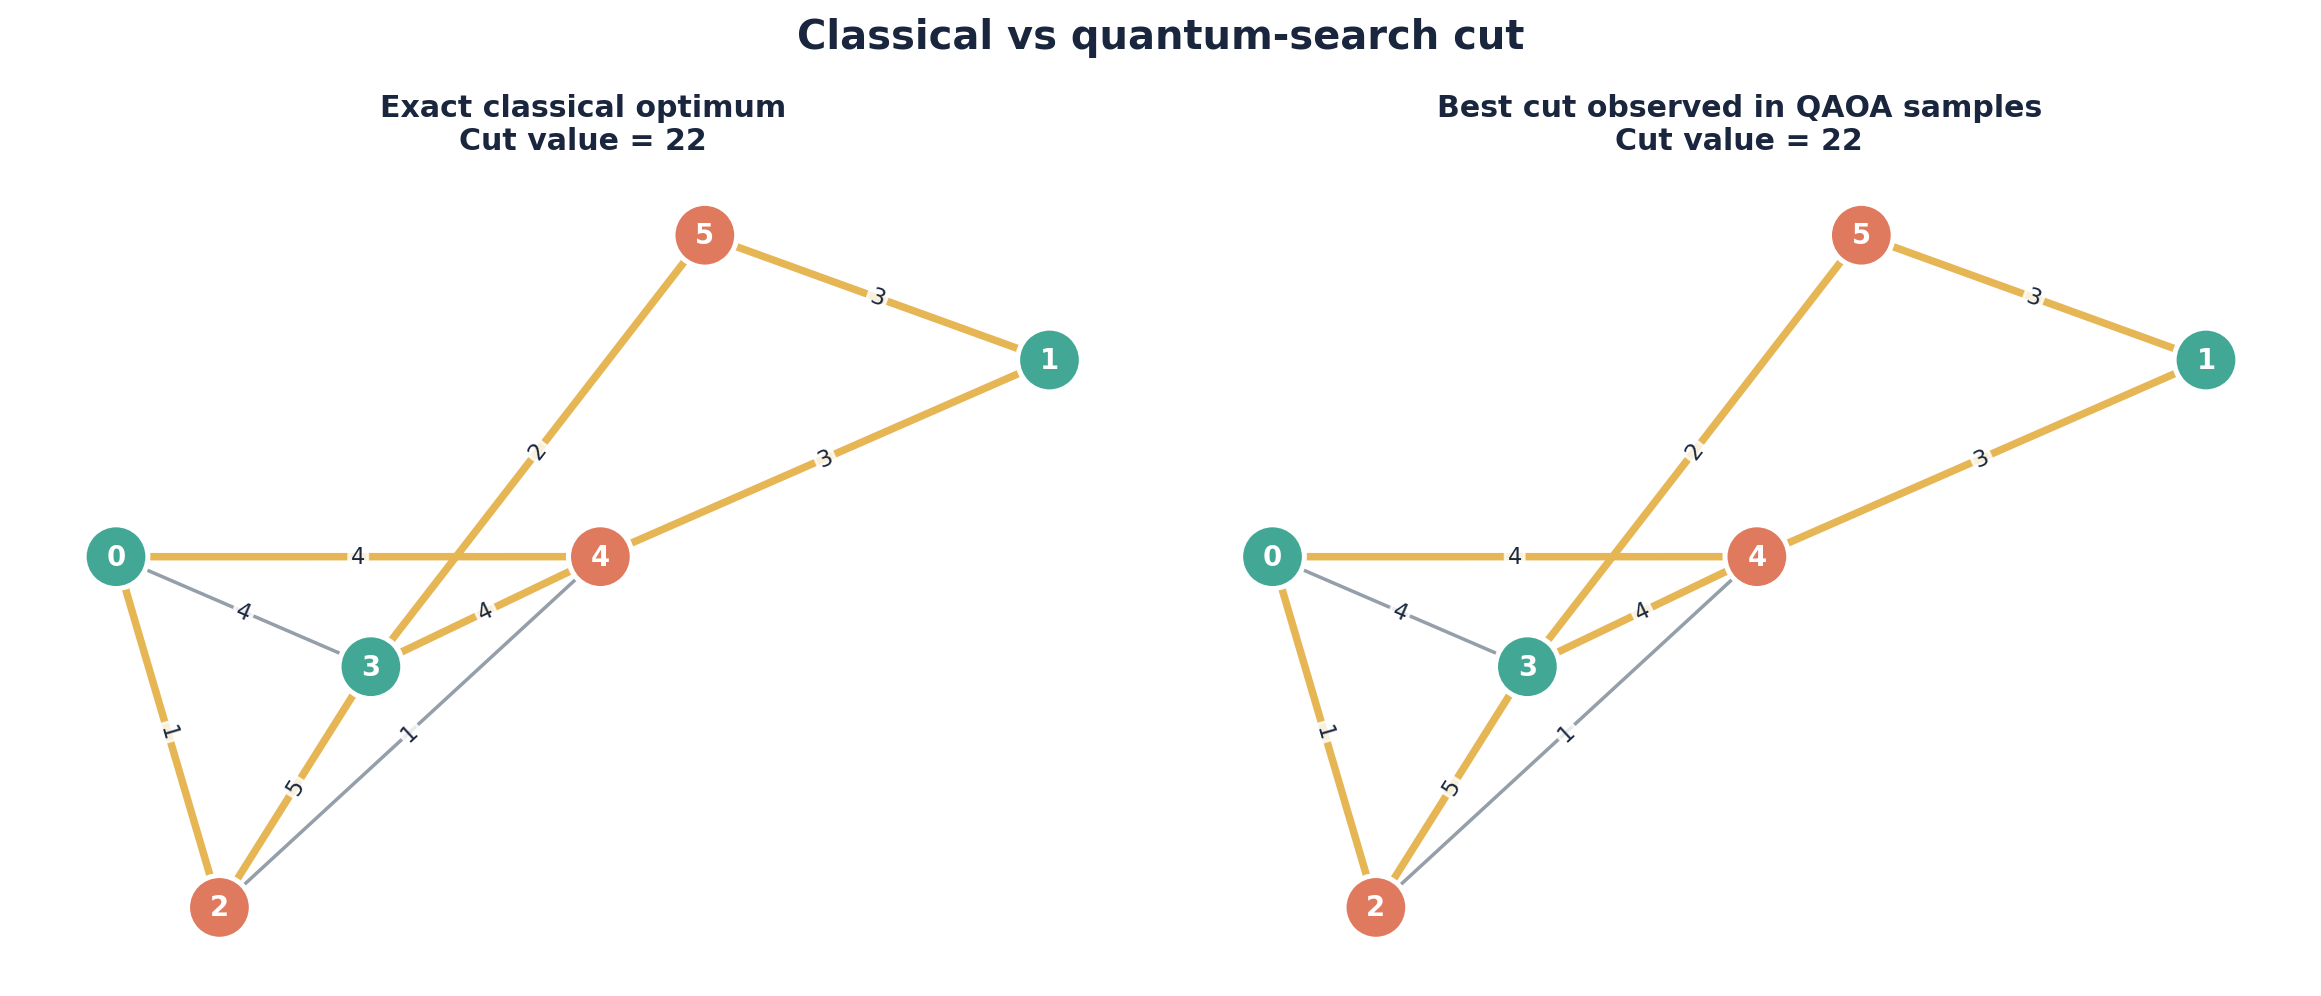

In [7]:
for depth in [1, 2]:
    repeats = pd.read_csv(ROOT / f'results/tables/sampling_repetitions_p{depth}.csv')
    display(repeats.groupby(['processor', 'mode']).agg(mean_cut=('expected_cut_from_samples', 'mean'), between_run_sd=('expected_cut_from_samples', 'std'), mean_optimal_rate=('optimal_cut_shot_rate', 'mean')))
display(Image(filename=str(ROOT / 'results/figures/classical_vs_qaoa_cut_p2.png')))

## Local guide audit and interpretation

The audit checks native coupling, full objective consistency, all saved histograms, source/artifact hashes and the official baseline. Both depths improve on uniform random partitions. B removes routing for this tailored instance; this does not imply universal superiority or quantum speedup. Full discussion and limitations are in `report.md`. Uploading the final repository and submitting its URL at the event portal remain external steps.

In [8]:
from validate_submission import audit
checks = audit(require_executed_notebook=False)
print('Local checks passed:', checks['checks_passed'])
print('Portal submission confirmed:', checks['external_requirements']['portal_submission_confirmed'])
display(Markdown(filename=str(ROOT / 'report.md')))

Local checks passed: 313
Portal submission confirmed: False


# PS-O1: Weighted Max-Cut QAOA and processor co-design

**Qiskit Fall Fest 2026, Phase 1**  
**Authors:** Inderpreet Kaur and Harshit Tripathi.  
**Problem:** exactly PS-O1. All results below come from the included executable code.

## 1. Problem and classical reference

The objective is to maximize crossing edge weight on the six-node NetworkX graph generated with `n=6`, `p=0.5`, and topology seed 42. Weights use NumPy `default_rng(42)`, sampled as integers from 1 to 5 in sorted edge order; this seed is an explicit choice because the guide does not specify it. The nine edges have total weight 27, so uniform independent partitions have expected cut 13.5.

The exact optimum is **22**. A representative partition is node bits **001011**, i.e. group 0 = {0,1,3} and group 1 = {2,4,5}. Its crossing weights are 1+4+3+3+5+4+2=22. Both all-64 full assignments and all-32 reduced assignments are enumerated; exported tables retain every reduced cut.

![Weighted graph](results/figures/01_original_weighted_graph.png)
![Classical solution](results/figures/02_classical_optimum_cut.png)

## 2. Five-qubit formulation and QAOA

Complementing all six bits leaves every crossing edge unchanged. Fixing node 0 to 0 selects exactly one representative of each complementary pair and preserves the full set of attainable cut values. Logical `q0...q4` encode nodes 1...5. This objective-preserving reduction fits the five-qubit budget; its free-variable mixer defines a reduced ansatz, whose finite-p distribution need not equal an unreduced six-qubit QAOA distribution.

The diagonal cost Hamiltonian is

$$C=\sum_{(u,v)\in E}\frac{w_{uv}}{2}(I-Z_uZ_v),\quad Z_0=+1.$$

For an edge touching node 0 the interaction becomes a single Z. The stored `SparsePauliOp` retains the identity offset, so its diagonal matches classical cut values exactly. Starting from the uniform superposition, each QAOA layer uses `exp(-i gamma C)` and `exp(-i beta sum X)`. Omitting the irrelevant identity phase yields `RZ(-gamma*w)` and `RZZ(-gamma*w)`; the mixer is `RX(2*beta)`. A test explicitly checks the sign convention against diagonal phase evolution.

For p=1, a 65-by-41 gamma/beta grid across `[0,2*pi)` and `[0,pi)` supplies separated starting points. COBYLA refines 16 starts with up to 800 evaluations each and tolerance 1e-7. p=2 uses the optimized p=1 state as a feasible starting point, a split-layer start, and seeded random starts. Every objective evaluation is saved and the best evaluated angles are retained, including when a local run stops at its budget. The fast NumPy objective is independently verified against Qiskit Statevector. This search makes no global variational optimality claim.

| p | Gammas (radians) | Betas (radians) | Exact ideal mean | Mean ratio | Objective evaluations |
| --- | --- | --- | --- | --- | --- |
| 1 | 0.1715265 | 0.3907392 | 17.642993 | 0.801954 | 3772 |
| 2 | 0.1368719, 0.2917845 | 0.4514599, 0.2598094 | 19.240690 | 0.874577 | 4633 |

![p=1 convergence](results/figures/qaoa_convergence_p1.png)
![p=2 convergence](results/figures/qaoa_convergence_p2.png)

## 3. Architecture design and controlled comparison

| Processor | Physical qubits | Undirected edges | Diameter | Maximum degree | Density |
| --- | --- | --- | --- | --- | --- |
| Processor A | 5 | 4 | 4 | 2 | 0.400 |
| Processor B | 9 | 12 | 4 | 4 | 0.333 |

A is the five-node chain. B's core links are `(0,3),(0,4),(1,2),(1,3),(2,3),(2,4)`, the six logical pair interactions. Its remaining six links connect the four additional physical qubits into a sparse connected extension. Three original graph edges touching fixed node 0 become single-qubit phases, so they require no coupling links. B is a specific algorithm/architecture co-design; the four extra nodes are idle for this primary identity-layout instance, and the connectivity of the active core accounts for its routing advantage.

![Processor A](results/figures/architecture_processor_A.png)
![Processor B](results/figures/architecture_processor_B.png)

The same optimized angles, logical gate order, identity initial placement, optimization level 1, transpiler seed 42, and native basis `rz,sx,x,cx` are used on both processors. Initial placement is declared explicitly; an adaptive layout search might reduce A's routing burden, so these numbers are conditional on that policy. Tests additionally check a non-identity placement on both processors.

SWAPs are counted by an analysis-only `post_routing` hook before translation in the same preset pass manager that generates the simulated circuit. A separate target basis is never used to infer this count. Final basis circuits contain zero literal SWAPs because translation decomposes them. Extra CX count relative to an unconstrained compile is reported separately, and is not assumed to be a SWAP count. Final optimization can cancel CX gates, so the two measures need not scale as exactly three CX per SWAP.

Every final CX is checked against the coupling graph. The five measured physical qubits are reordered by destination classical bit after routing; the ideal output probabilities are then compared with the logical reference. The largest recorded deviation is below 1e-10. Gate count excludes measurement/barriers, while reported circuit depth includes the final measurements; unitary depth is also saved.

## 4. Noise, metrics and statistical interpretation

Both processors use one-qubit depolarizing parameter 0.001 on `rz,sx,x`, CX depolarizing parameter 0.005, and independent symmetric readout flip probability 0.01. These are the guide's synthetic rates, rather than measured hardware error rates. RZ receives depolarizing noise even though some physical platforms implement it virtually; this choice is held identical on A/B.

Exact ideal statevectors establish compiler equivalence. Exact noisy density matrices establish the effect of gate noise; applying the independent readout confusion channel to the saved pre-measurement probabilities incorporates readout error once. Full 32-outcome ideal/noisy probabilities are exported. Separate Aer evaluations sample 4096 shots each, for five seeds (42-46), for both noise modes and depths. The official primary comparison uses seed 42; repetitions quantify sampling sensitivity.

The mean approximation ratio is `E[cut]/22`. The best-observed ratio is also saved, but reaching 22 in one sample does not mean the mean ratio is 1. Optimal-cut probability is the total probability of all exact-optimum outcomes. Mean-cut uncertainty uses sample standard deviation / sqrt(shots), with approximate 95% normal intervals; optimal-cut rate uses Wilson 95% intervals.

The classical distribution fidelity is `(sum sqrt(p_logical*p_output))^2`, in [0,1], and total variation is `sum abs(p_logical-p_output)/2`. These describe measurement distributions, not quantum state fidelity or a proof of computational advantage.

## 5. Resource counts and exact modeled noise results

| p | Processor | Depth | CX | Routing SWAPs | Exact noisy mean cut | Mean ratio | P(optimum) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Processor A | 38 | 27 | 5 | 17.1530 | 0.7797 | 13.32% |
| 1 | Processor B | 21 | 12 | 0 | 17.3180 | 0.7872 | 13.88% |
| 2 | Processor A | 69 | 51 | 9 | 18.1763 | 0.8262 | 18.30% |
| 2 | Processor B | 38 | 24 | 0 | 18.5631 | 0.8438 | 19.84% |

At p=1, B reduces depth by **44.7%** and CX count by **55.6%**. A inserts 5 SWAPs and B inserts 0. Exact noisy expected cut is higher on B by **0.165051**. The exact result removes sampling uncertainty from that comparison, within the stated model and compilation policy.

At p=2, B reduces depth by **44.9%** and CX count by **52.9%**. A inserts 9 SWAPs and B inserts 0. Exact noisy expected cut is higher on B by **0.386808**. The exact result removes sampling uncertainty from that comparison, within the stated model and compilation policy.

![p=1 resources](results/figures/processor_comparison_p1.png)
![p=2 resources](results/figures/processor_comparison_p2.png)

## 6. Shot-based results and repetition check

| p | Processor | Ideal shot mean | Noisy shot mean | Noisy mean 95% CI | Mean ratio | Optimum shot rate | Best cut |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Processor A | 17.6936 | 17.2183 | [17.0996, 17.3369] | 0.7826 | 13.87% | 22 |
| 1 | Processor B | 17.6670 | 17.3914 | [17.2767, 17.5060] | 0.7905 | 14.31% | 22 |
| 2 | Processor A | 19.2385 | 18.1768 | [18.0597, 18.2939] | 0.8262 | 19.07% | 22 |
| 2 | Processor B | 19.1948 | 18.5635 | [18.4567, 18.6702] | 0.8438 | 20.46% | 22 |

Five repetitions, 4096 shots per evaluation:

| p | Processor | Runs | Total noisy shots | Mean of run means | SD of run means | Mean optimum rate |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Processor A | 5 | 20480 | 17.1510 | 0.0415 | 13.49% |
| 1 | Processor B | 5 | 20480 | 17.3406 | 0.0302 | 14.08% |
| 2 | Processor A | 5 | 20480 | 18.1907 | 0.0493 | 18.51% |
| 2 | Processor B | 5 | 20480 | 18.5669 | 0.0345 | 20.12% |

The noisy samples are consistent with the exact noisy predictions. Small ideal sample differences between A and B come from finite-shot sampling; exact ideal distributions agree. Noise can redistribute probability toward particular cuts, so an optimal-hit rate need not decline monotonically for arbitrary parameter choices. Here, expected-cut degradation and distribution fidelity provide broader indicators.

![p=1 shot distributions](results/figures/noisy_cut_distribution_p1.png)
![p=2 shot distributions](results/figures/noisy_cut_distribution_p2.png)
![Best sampled solution](results/figures/classical_vs_qaoa_cut_p2.png)

## 7. Depth trade-off, interpretation and limitations

p=2 increases the exact ideal expected cut and the exact noisy expected cut for both architectures compared with p=1. It also nearly doubles the pair-interaction gate budget and increases noise accumulation. On this instance the improvement in variational expressivity outweighs that additional noise cost at the stated rates; deeper circuits beyond p=2 were not studied.

The experiment supports the conclusion that B's active core removes routing overhead for this reduced graph, lowering native depth and CX count and improving the exact noisy objective. This is a controlled simulation with uniform gate noise and fixed layout, rather than a universal ranking of processor quality.

- Only one generated topology and weight assignment is benchmarked. B was explicitly tailored to its interactions, and its four spare qubits do not participate in the primary circuit.
- Initial layout and seeded compiler heuristics affect overhead. Better layout or alternative gate scheduling could change A's results.
- The symmetry reduction preserves the optimization objective but changes the finite-depth ansatz compared with a six-qubit mixer.
- Grid/multistart COBYLA avoids several poor local solutions but provides no certificate of the best possible QAOA angles.
- Synthetic independent depolarizing/readout channels omit relaxation, crosstalk, timing and device-dependent errors. No real quantum processor was used.
- Exact classical enumeration is trivial for this graph. Sampling an optimal cut does not establish quantum speedup or scalability.
- Confidence intervals describe shot variation only, not model bias or robustness to new graph instances.

## 8. Reproducibility and evidence

The notebook executes the entire experiment in a fresh Python kernel. The runner exports weighted inputs, every reduced classical cut, Hamiltonian terms, optimizer traces and restarts, optimized angles, QPY circuit files, exact output probabilities, all sampled histograms, processor summaries, figures and environment manifests. Unit tests check the objective and circuit with independent calculations. The submission validator recomputes metrics and verifies source/artifact SHA256 hashes to reject stale results.

Primary command: `python run_experiment.py` (both depths; 4096 shots per evaluation; seeds 42-46; 16 optimization starts; up to 800 evaluations/start). Run `python -m pytest -q`, `python execute_notebook.py`, and `python validate_submission.py` for the complete local validation. The source zip had no Git metadata; the public upstream inspected before finalization was commit `8c1dcb92612e9fab14b2b42fedc09b8033a84ea2`. Source content hashes identify the final local run independently of its eventual Git commit.

| Package | Validated version |
| --- | --- |
| Python | 3.14.7 |
| numpy | 2.3.5 |
| pandas | 2.3.3 |
| matplotlib | 3.10.8 |
| networkx | 3.6.1 |
| scipy | 1.17.0 |
| qiskit | 2.5.0 |
| qiskit-aer | 0.17.2 |
| nbformat | 5.11.1 |
| nbclient | 0.11.0 |
| ipykernel | 7.4.0 |
| pytest | 9.1.1 |

## 9. Master-guide requirement mapping

| Guide requirement | Evidence | Local state |
| --- | --- | --- |
| One selected PS; team of 2-6 | README and submission.json; PS-O1; two named members | Complete |
| Six-node graph, p=1 or p=2, classical reference | Both allowed depths; saved inputs and full/reduced enumeration | Complete |
| Participant-defined A(5q)/B(9q), valid basis and common baseline | Processor JSON, routing checks, saved QPY | Complete |
| Depth, CX, SWAP overhead and solution accuracy | Comparison CSVs; exact/noisy objective, ratios, success and fidelity | Complete |
| Required modular structure, including routing.py | Root notebook and src modules | Complete |
| Pinned dependencies and reproducible notebook | Direct/full locks; fresh-kernel execution | Complete after execution audit |
| Architectural analysis and legible figures | This report; graph, coupling and benchmark plots | Complete |
| Final public GitHub content and portal submission | Repository URL and external portal acceptance | Requires upload/submission confirmation |

The deadline in the supplied guide is **October 14, 2026, 23:59 IST**. Local correctness and packaging cannot verify event registration or portal acceptance. `submission.json` intentionally records portal confirmation as false until the team completes that external step. No Phase 2 Processor C/D deliverables are required.

## References

- Supplied Qiskit Fall Fest 2026 Phase 1 Master Challenge Guide: pp. 1-3 (scope, benchmark, structure), p. 4 (PS-O1), p. 7 (rubric/checklist).
- [Qiskit transpiler and stage hooks](https://quantum.cloud.ibm.com/docs/en/api/qiskit/transpiler).
- [Qiskit Aer simulator documentation](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html).
